<a href="https://colab.research.google.com/github/ahmad03amer/AJTest/blob/main/1255267_Assignment1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Computer Vision – MSAI6330
# Assignment 1

**Student ID:** 1255267

This notebook implements image loading and grayscale conversion, Canny edge detection, Gaussian smoothing, salt-and-pepper denoising, and Laplacian pyramid blending (Burt & Adelson, 1983).

**Libraries:** Python, OpenCV (`cv2`), NumPy, Matplotlib.

In [11]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

IMAGE_DIR = "."

UNI_PATH = f"{IMAGE_DIR}/uni.jpeg"
APPLE_PATH = f"{IMAGE_DIR}/apple.jpg"
ORANGE_PATH = f"{IMAGE_DIR}/orange.jpg"


def show_bgr(img, title=""):
    """Display a BGR OpenCV image correctly in Matplotlib."""
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")


def show_gray(img, title=""):
    plt.imshow(img, cmap="gray", vmin=0, vmax=255)
    plt.title(title)
    plt.axis("off")


def load_or_fail(path):
    img = cv2.imread(path)
    if img is None:
        raise FileNotFoundError(
            f"Could not read '{path}'. Upload the file in Colab (left Files panel) "
            "or set IMAGE_DIR to the folder that contains it."
        )
    return img

## Task 1: Image Loading and Grayscale Conversion

**What is expected:** read `uni.jpeg` with OpenCV, show the color original, convert to grayscale, show the grayscale image.

**Why grayscale:** later tasks (Canny, Gaussian comparison, salt-and-pepper) operate on intensity. Color would add three channels without helping edge/noise analysis here.

Original shape (H, W, C): (476, 645, 3)
Grayscale shape (H, W): (476, 645)
Dtype: uint8 | value range: 0 - 255


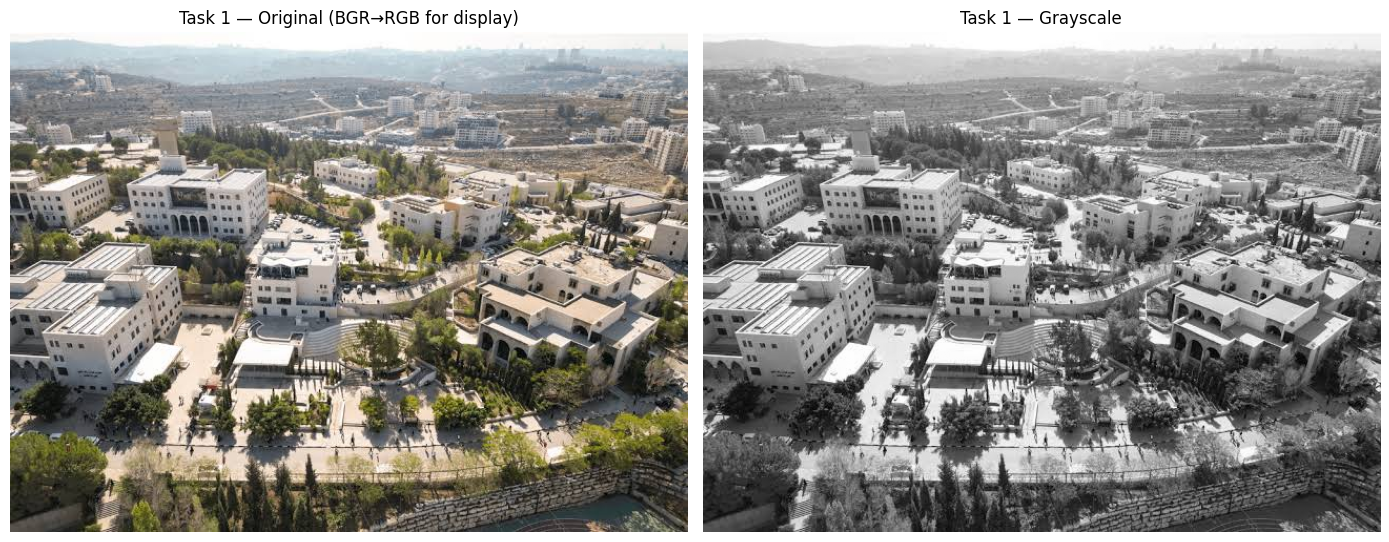

In [5]:
uni_bgr = load_or_fail(UNI_PATH)
uni_gray = cv2.cvtColor(uni_bgr, cv2.COLOR_BGR2GRAY)

print("Original shape (H, W, C):", uni_bgr.shape)
print("Grayscale shape (H, W):", uni_gray.shape)
print("Dtype:", uni_gray.dtype, "| value range:", uni_gray.min(), "-", uni_gray.max())

plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)
show_bgr(uni_bgr, "Task 1 — Original (BGR→RGB for display)")
plt.subplot(1, 2, 2)
show_gray(uni_gray, "Task 1 — Grayscale")
plt.tight_layout()
plt.show()

### Task 1 observation

The original aerial campus photo is a 3-channel BGR image. After `cv2.cvtColor(..., COLOR_BGR2GRAY)`, each pixel is a single intensity in `[0, 255]`. Buildings, paths, and vegetation remain visible because they differ in brightness, but hue (red roofs vs green trees) is discarded. This grayscale image is reused in Tasks 2–4.

## Task 2: Edge Detection Using Canny

**What is expected:** Canny on the Task 1 grayscale image; grayscale and edges side by side; report lower/upper thresholds and how changing them affects edges.

**Why Canny:** it combines Gaussian smoothing, gradient magnitude/orientation, non-maximum suppression, and hysteresis thresholding. That usually gives cleaner building/path outlines than a raw Sobel magnitude map.

**Hysteresis:**
- pixels **above the upper threshold** are strong edges (kept)
- pixels **below the lower threshold** are discarded
- pixels **in between** are kept only if they connect to a strong edge

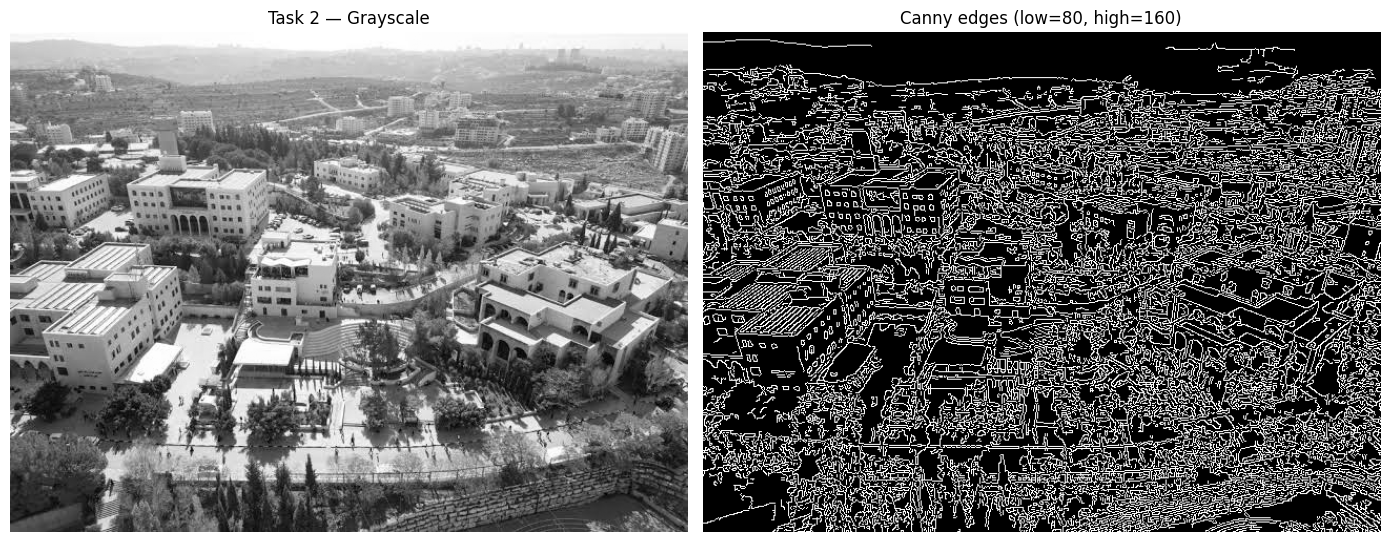

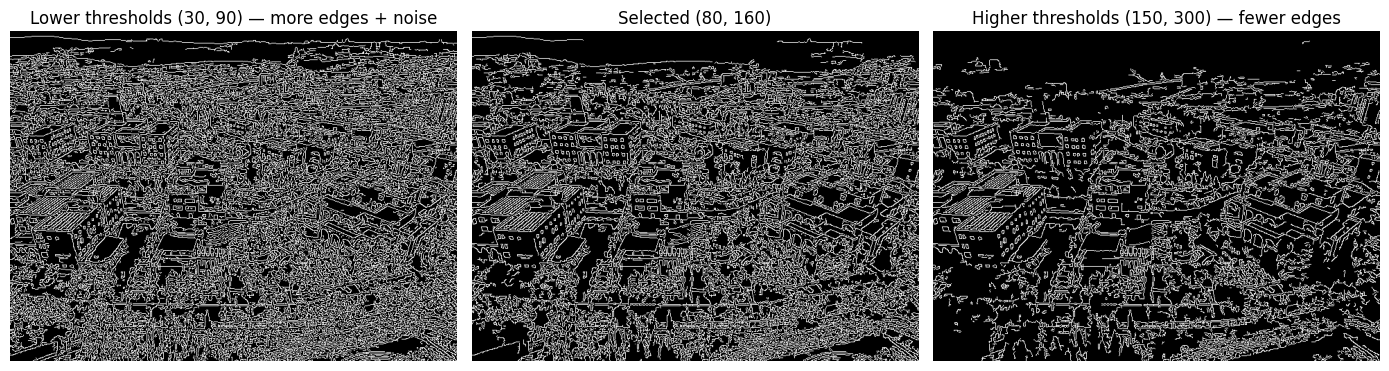

In [17]:
# Chosen after trying several pairs on this image.
# Ratio ~1:2 to 1:3 is the usual starting point (OpenCV docs).
CANNY_LOW = 80
CANNY_HIGH = 160

edges = cv2.Canny(uni_gray, CANNY_LOW, CANNY_HIGH)

# Extra comparison so the write-up is not only one pair of numbers
edges_loose = cv2.Canny(uni_gray, 30, 90)
edges_strict = cv2.Canny(uni_gray, 150, 300)

plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)
show_gray(uni_gray, "Task 2 — Grayscale")
plt.subplot(1, 2, 2)
show_gray(edges, f"Canny edges (low={CANNY_LOW}, high={CANNY_HIGH})")
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 5))
plt.subplot(1, 3, 1)
show_gray(edges_loose, "Lower thresholds (30, 90) — more edges + noise")
plt.subplot(1, 3, 2)
show_gray(edges, "Selected (80, 160)")
plt.subplot(1, 3, 3)
show_gray(edges_strict, "Higher thresholds (150, 300) — fewer edges")
plt.tight_layout()
plt.show()

### Task 2 discussion

**Selected thresholds: lower = 80, upper = 160** (ratio 1:2).

Canny turns the grayscale campus into a binary edge map: smooth sky and open ground stay black; intensity jumps become thin white curves after non-maximum suppression.

On this photo, **(80, 160)** keeps buildings, roads, and the stone wall, but the scene has a lot of high-frequency texture, so trees and pavement still produce many edges. That is expected for an aerial image; it is not a failure of Canny.

**Changing the thresholds:**
- **(30, 90)** — more weak gradients survive (foliage, shadows, JPEG noise). The map is busier.
- **(80, 160)** — reported pair: campus layout is readable, with some vegetation edges still present.
- **(150, 300)** — only strong contrast remains (building silhouettes, hard shadows). Fine texture disappears.

Widening the gap (e.g. 50, 200) keeps mid-strength edges only if they touch a strong edge. Narrowing it (e.g. 100, 120) makes hysteresis almost a single cutoff. Exact values are image-dependent, which is why they must be reported.

## Task 3: Gaussian Filtering and Comparison

**What is expected:**
1. One Gaussian blur of the grayscale image with $\sigma = 2\sqrt{2}$
2. Two successive Gaussian blurs, each with $\sigma = 2$
3. Show both results
4. Absolute pixel-wise difference
5. Explain what you see

**Why this experiment:** Gaussian filters are separable and **compose in variance**. Two 1-D (or 2-D) Gaussians with standard deviations $\sigma_1$ and $\sigma_2$ equal one Gaussian with

$$\sigma_{\text{eq}} = \sqrt{\sigma_1^2 + \sigma_2^2}$$

Here $\sqrt{2^2 + 2^2} = \sqrt{8} = 2\sqrt{2}$. So the two pipelines should match, up to discrete kernel rounding.

`ksize=(0, 0)` lets OpenCV choose an odd kernel from $\sigma$ (`cv2.GaussianBlur`).

σ once = 2.828427
Difference: min=0, max=1, mean=0.0768
A max near 0–2 and a very small mean support theoretical equivalence.


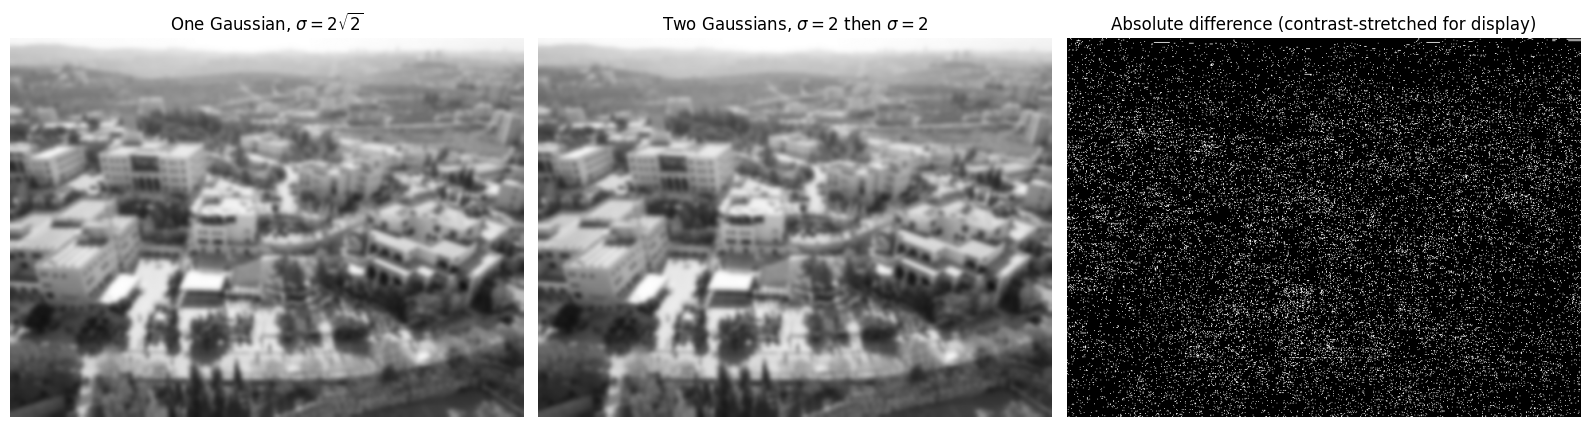

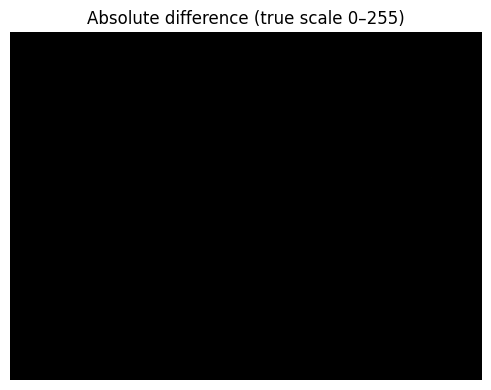

In [18]:
sigma_once = 2.0 * np.sqrt(2.0)  # 2√2 ≈ 2.828
sigma_twice = 2.0

# Single filter with σ = 2√2
gauss_once = cv2.GaussianBlur(uni_gray, ksize=(0, 0), sigmaX=sigma_once, sigmaY=sigma_once)

# Two filters with σ = 2 each
gauss_twice = cv2.GaussianBlur(uni_gray, ksize=(0, 0), sigmaX=sigma_twice, sigmaY=sigma_twice)
gauss_twice = cv2.GaussianBlur(gauss_twice, ksize=(0, 0), sigmaX=sigma_twice, sigmaY=sigma_twice)

# Absolute difference (uint8 images → use absdiff or convert to int)
diff = cv2.absdiff(gauss_once, gauss_twice)

print(f"σ once = {sigma_once:.6f}")
print(f"Difference: min={diff.min()}, max={diff.max()}, mean={diff.mean():.4f}")
print("A max near 0–2 and a very small mean support theoretical equivalence.")

plt.figure(figsize=(16, 5))
plt.subplot(1, 3, 1)
show_gray(gauss_once, r"One Gaussian, $\sigma=2\sqrt{2}$")
plt.subplot(1, 3, 2)
show_gray(gauss_twice, r"Two Gaussians, $\sigma=2$ then $\sigma=2$")
plt.subplot(1, 3, 3)
# Scale difference for visibility; report that we amplified it
diff_vis = cv2.normalize(diff, None, 0, 255, cv2.NORM_MINMAX)
show_gray(diff_vis, "Absolute difference (contrast-stretched for display)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
show_gray(diff, "Absolute difference (true scale 0–255)")
plt.tight_layout()
plt.show()

### Task 3 discussion

The two blurred images look the same: fine texture (trees, pavement) is reduced, while large structures (buildings) remain.

That is predicted by Gaussian composition. Variances add:

$$\sigma_{\text{eq}} = \sqrt{2^2 + 2^2} = \sqrt{8} = 2\sqrt{2}$$

so two filters with $\sigma = 2$ equal one filter with $\sigma = 2\sqrt{2}$.

On this image the absolute difference is **min = 0, max = 1, mean ≈ 0.077** gray levels. The **true-scale** difference is almost black, so the two results are equivalent for any practical purpose.

The leftover error is discretization, not a different amount of blur:
- OpenCV uses a **truncated discrete kernel**, not an infinite continuous Gaussian
- two `uint8` rounding passes versus one

The **contrast-stretched** panel looks noisy only because those 0–1 errors were scaled to 0–255. It does not mean the images differ in a visually important way.

If the true-scale difference were bright and structured, $\sigma$ or kernel size would be wrong (for example $\sigma = \sqrt{2}$ twice, or a `ksize` too small to cover about $3\sigma$).

## Task 4: Salt-and-Pepper Noise Removal

**What is expected:** grayscale `uni.jpeg`; **30%** of pixels randomly set to 0 or 255; show noisy image; denoise with Gaussian, median, and bilateral; choose parameters; show the three results side by side; say which filter is best and why.

**Why 30% is hard:** almost one in three pixels is impulse noise. Linear averages (Gaussian) pull neighbors toward 0/255 and smear edges. Bilateral still averages intensities, so impulses remain as speckles. Median replaces a pixel by the neighborhood rank statistic, which ignores extreme 0/255 values if they are not the majority in the window.

Fraction of pixels changed: 0.299 (target 0.30)


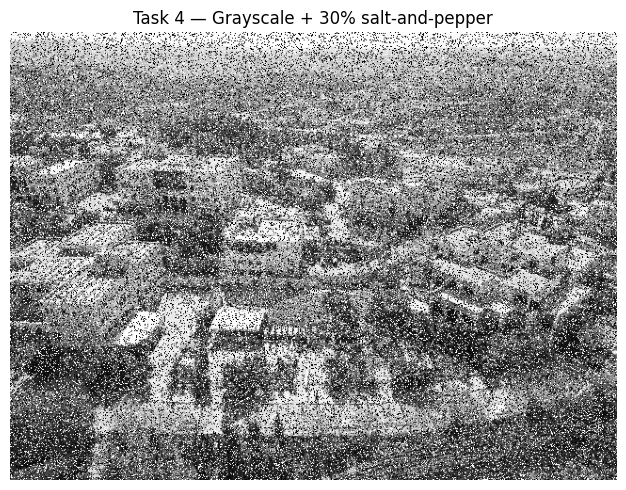

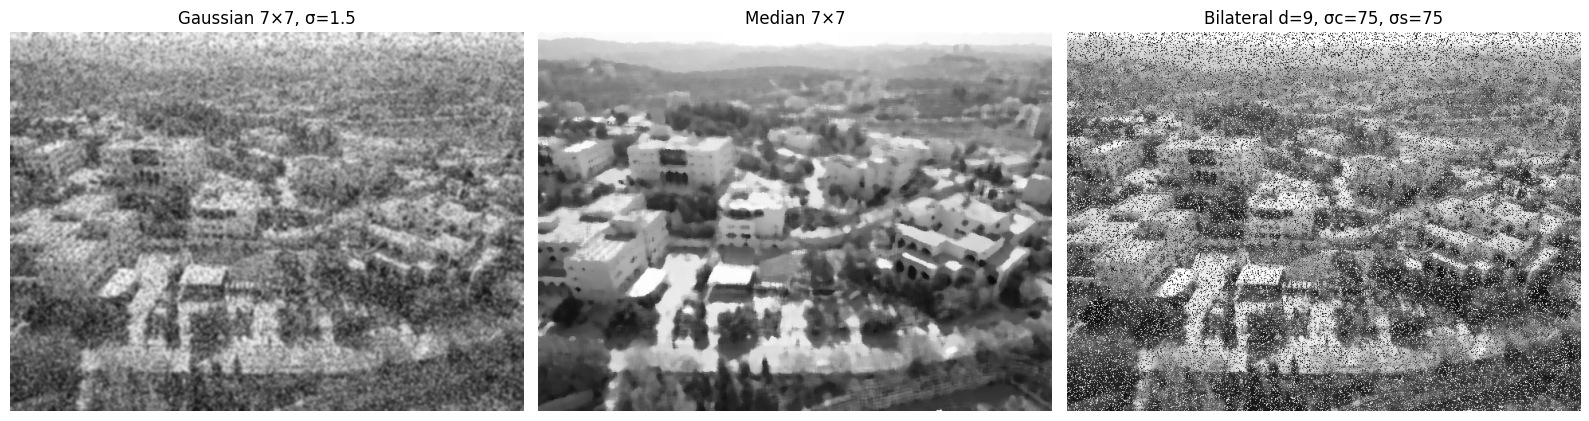

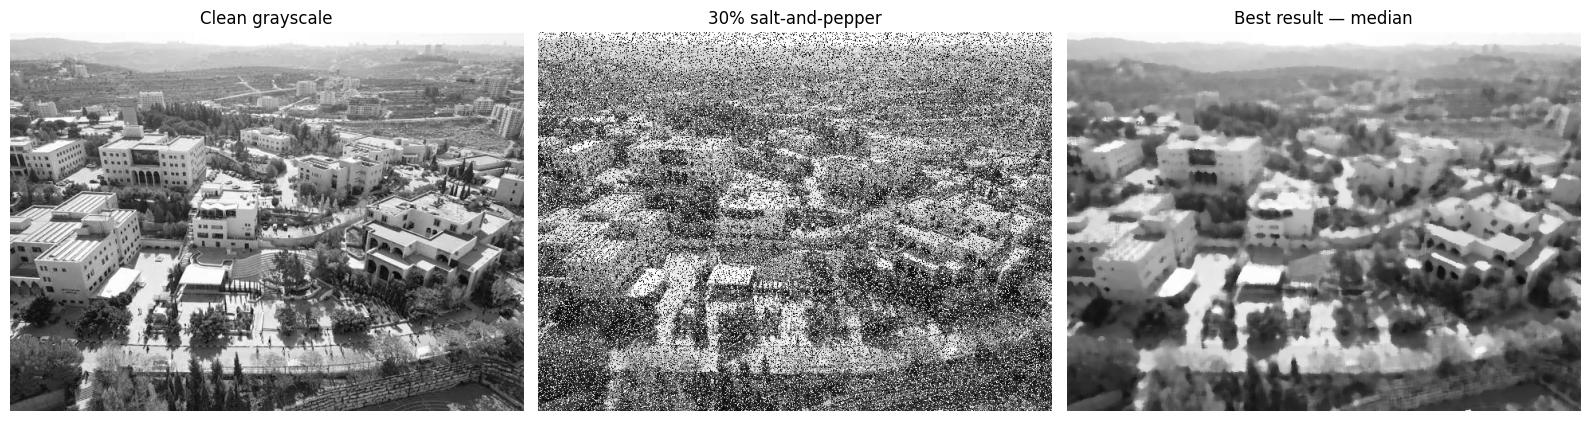

In [19]:
rng = np.random.default_rng(42)  # reproducible; change/remove if you prefer a new pattern

def add_salt_and_pepper(gray, amount=0.30, rng=rng):
    noisy = gray.copy()
    h, w = gray.shape
    n = int(amount * h * w)
    idx = rng.choice(h * w, size=n, replace=False)
    ys, xs = np.unravel_index(idx, (h, w))
    salt = rng.random(n) < 0.5
    noisy[ys[salt], xs[salt]] = 255
    noisy[ys[~salt], xs[~salt]] = 0
    return noisy

noisy = add_salt_and_pepper(uni_gray, amount=0.30)
actual_ratio = np.mean(noisy != uni_gray)
print(f"Fraction of pixels changed: {actual_ratio:.3f} (target 0.30)")

plt.figure(figsize=(7, 5))
show_gray(noisy, "Task 4 — Grayscale + 30% salt-and-pepper")
plt.tight_layout()
plt.show()

# --- Parameter choices (tuned visually on this image) ---
# Gaussian: larger σ / ksize smooths noise but blurs buildings. 7×7, σ=1.5 is a compromise.
gauss_denoise = cv2.GaussianBlur(noisy, ksize=(7, 7), sigmaX=1.5, sigmaY=1.5)

# Median: odd ksize. 5 is often too weak at 30% noise; 7 removes most impulses
# without destroying large edges as much as Gaussian.
median_denoise = cv2.medianBlur(noisy, 7)

# Bilateral: range+space Gaussian. Good for Gaussian noise + edges, weak on impulses.
# d=9, sigmaColor=75, sigmaSpace=75 are common starting values.
bilateral_denoise = cv2.bilateralFilter(noisy, d=9, sigmaColor=75, sigmaSpace=75)

plt.figure(figsize=(16, 5))
plt.subplot(1, 3, 1)
show_gray(gauss_denoise, "Gaussian 7×7, σ=1.5")
plt.subplot(1, 3, 2)
show_gray(median_denoise, "Median 7×7")
plt.subplot(1, 3, 3)
show_gray(bilateral_denoise, "Bilateral d=9, σc=75, σs=75")
plt.tight_layout()
plt.show()

# Optional: original vs noisy vs best (helps the comparison paragraph)
plt.figure(figsize=(16, 5))
plt.subplot(1, 3, 1)
show_gray(uni_gray, "Clean grayscale")
plt.subplot(1, 3, 2)
show_gray(noisy, "30% salt-and-pepper")
plt.subplot(1, 3, 3)
show_gray(median_denoise, "Best result — median")
plt.tight_layout()
plt.show()

### Task 4 comparison

| Filter | Parameters used | Impulse noise | Edges / detail |
|---|---|---|---|
| Gaussian | 7×7, σ = 1.5 | Speckles become gray blobs; image looks foggy | Buildings and paths blur |
| Median | 7×7 | Most black/white dots disappear | Large edges stay; very thin lines may nick |
| Bilateral | d = 9, σ_color = 75, σ_space = 75 | Many 0/255 pixels remain (they are not “similar” to neighbors, so they are not averaged away) | Edges that survived the noise stay sharp |

**Best for this noise: median filter.** Salt-and-pepper is **impulse** noise, not additive Gaussian noise. The median is robust to outliers. Gaussian is a linear low-pass filter and treats 0 and 255 as valid samples, so it smears them. Bilateral is designed to **preserve** pixels that differ a lot from the neighborhood, which is the opposite of what impulse denoising needs.

Larger median windows (9, 11) remove more residual dots but start to flatten windows and railings. 7×7 was the best visual trade-off on this 30% example. A smaller Gaussian does not remove 30% impulses; a larger Gaussian only blurs more.

## Task 5: Image Blending Using Laplacian Pyramids

**What is expected (Burt & Adelson, 1983):** read `apple.jpg` and `orange.jpg`; make sizes compatible; Gaussian pyramids; Laplacian pyramids; a mask and its Gaussian pyramid; blend each Laplacian level with the mask; reconstruct; show originals and the composite (apple left / orange right, seamless seam).

**Why pyramids, not a hard cut or a simple alpha blend:**
- A **hard split** makes a visible seam (different texture, lighting, and color).
- A **wide spatial alpha blend** at full resolution ghosts both fruits.
- A **Laplacian pyramid** blends **low frequencies over a wide region** (smooth lighting/color) and **high frequencies over a narrow region** (keep apple/orange texture). That is a multiresolution spline.

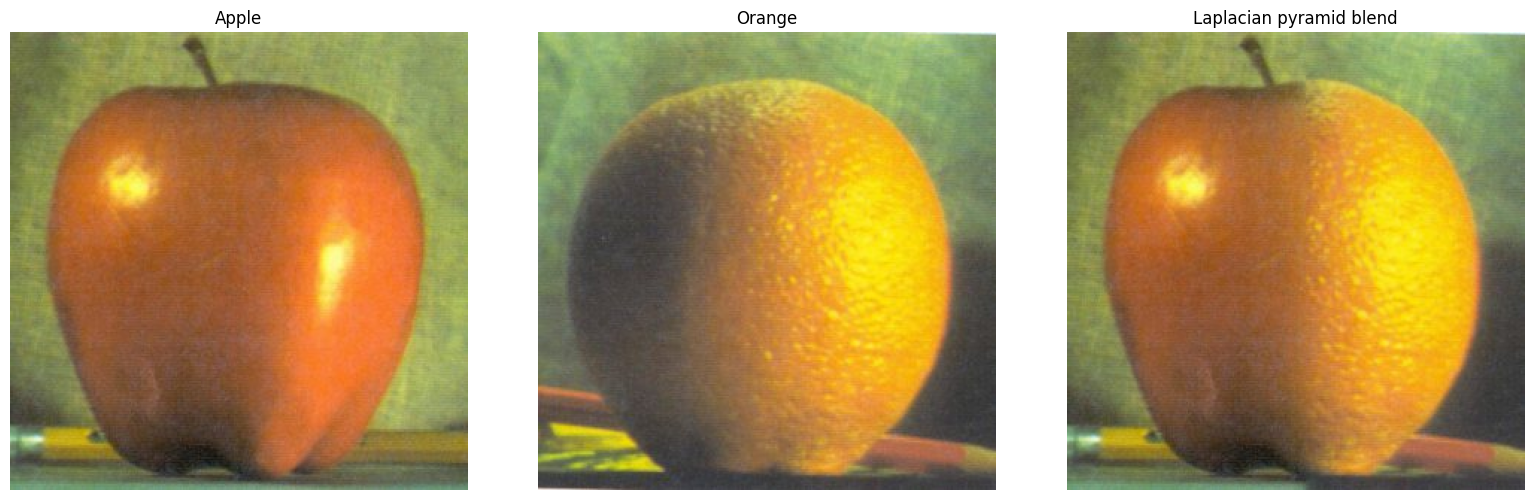

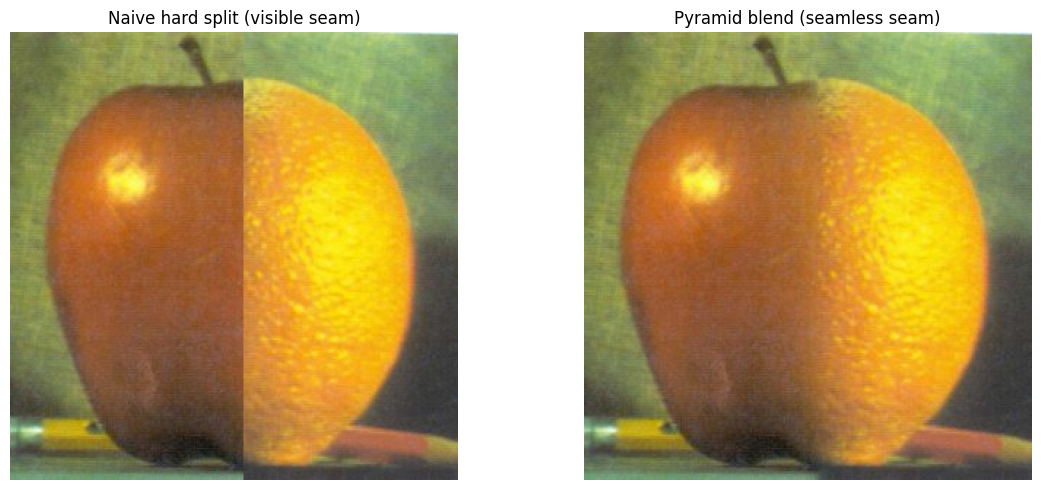

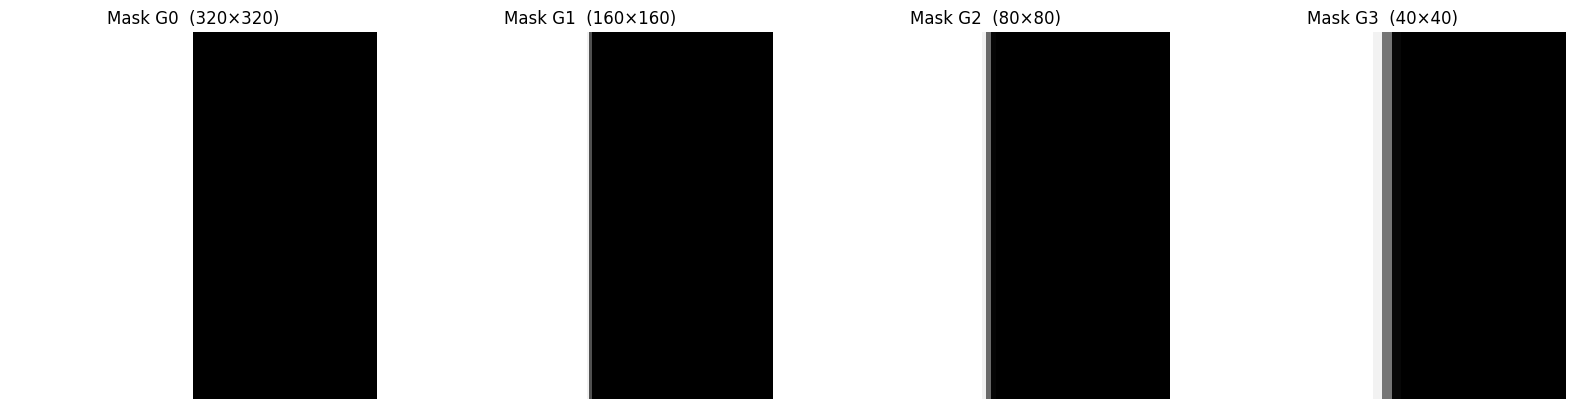

In [20]:
def make_same_size(a, b):
    """Resize both to a common size divisible by 2^(levels-1) so pyrDown/pyrUp align."""
    h = min(a.shape[0], b.shape[0])
    w = min(a.shape[1], b.shape[1])
    return cv2.resize(a, (w, h), interpolation=cv2.INTER_AREA), cv2.resize(b, (w, h), interpolation=cv2.INTER_AREA)


def pad_for_pyramid(img, levels):
    """Pad so height and width are divisible by 2^(levels-1)."""
    factor = 2 ** (levels - 1)
    h, w = img.shape[:2]
    new_h = int(np.ceil(h / factor) * factor)
    new_w = int(np.ceil(w / factor) * factor)
    top = 0
    bottom = new_h - h
    left = 0
    right = new_w - w
    padded = cv2.copyMakeBorder(img, top, bottom, left, right, cv2.BORDER_REFLECT_101)
    return padded, (h, w)


def gaussian_pyramid(img, levels):
    gp = [img.astype(np.float32)]
    current = gp[0]
    for _ in range(1, levels):
        current = cv2.pyrDown(current)
        gp.append(current)
    return gp


def laplacian_pyramid(gp):
    lp = []
    for i in range(len(gp) - 1):
        size = (gp[i].shape[1], gp[i].shape[0])  # (width, height)
        up = cv2.pyrUp(gp[i + 1], dstsize=size)
        lp.append(gp[i] - up)
    lp.append(gp[-1])  # coarsest residual = last Gaussian level
    return lp


def collapse_laplacian(lp):
    current = lp[-1]
    for i in range(len(lp) - 2, -1, -1):
        size = (lp[i].shape[1], lp[i].shape[0])
        current = cv2.pyrUp(current, dstsize=size) + lp[i]
    return current


def pyramid_blend(img_a, img_b, mask, levels=6):
    """
    img_a, img_b: BGR uint8, same size
    mask: 2D float32 in [0, 1], 1 = take A, 0 = take B
    """
    gp_a = gaussian_pyramid(img_a, levels)
    gp_b = gaussian_pyramid(img_b, levels)
    lp_a = laplacian_pyramid(gp_a)
    lp_b = laplacian_pyramid(gp_b)

    mask_3 = mask.astype(np.float32)
    if mask_3.ndim == 2:
        mask_3 = np.dstack([mask_3] * 3)
    gp_m = gaussian_pyramid(mask_3, levels)

    lp_blend = []
    for la, lb, gm in zip(lp_a, lp_b, gp_m):
        lp_blend.append(gm * la + (1.0 - gm) * lb)

    blended = collapse_laplacian(lp_blend)
    return np.clip(blended, 0, 255).astype(np.uint8), gp_a, gp_b, gp_m, lp_a, lp_b, lp_blend


LEVELS = 6

apple = load_or_fail(APPLE_PATH)
orange = load_or_fail(ORANGE_PATH)
apple, orange = make_same_size(apple, orange)
apple_p, orig_hw = pad_for_pyramid(apple, LEVELS)
orange_p, _ = pad_for_pyramid(orange, LEVELS)

h, w = apple_p.shape[:2]
# Vertical split: left = apple, right = orange (classic mosaic)
mask = np.zeros((h, w), dtype=np.float32)
mask[:, : w // 2] = 1.0

blended_p, gp_a, gp_b, gp_m, lp_a, lp_b, lp_blend = pyramid_blend(
    apple_p, orange_p, mask, levels=LEVELS
)

oh, ow = orig_hw
apple_show, orange_show, blended = apple[:oh, :ow], orange[:oh, :ow], blended_p[:oh, :ow]

# Direct hard cut vs pyramid (shows why the pyramid is needed)
hard = np.where(mask[:oh, :ow, None] > 0.5, apple_show, orange_show)

plt.figure(figsize=(16, 5))
plt.subplot(1, 3, 1)
show_bgr(apple_show, "Apple")
plt.subplot(1, 3, 2)
show_bgr(orange_show, "Orange")
plt.subplot(1, 3, 3)
show_bgr(blended, "Laplacian pyramid blend")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
show_bgr(hard, "Naive hard split (visible seam)")
plt.subplot(1, 2, 2)
show_bgr(blended, "Pyramid blend (seamless seam)")
plt.tight_layout()
plt.show()

n_show = min(4, LEVELS)
plt.figure(figsize=(16, 4))
for i in range(n_show):
    plt.subplot(1, n_show, i + 1)
    m = gp_m[i][:, :, 0]
    plt.imshow(m, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    plt.title(f"Mask G{i}  ({m.shape[1]}×{m.shape[0]})")
    plt.axis("off")
plt.tight_layout()
plt.show()

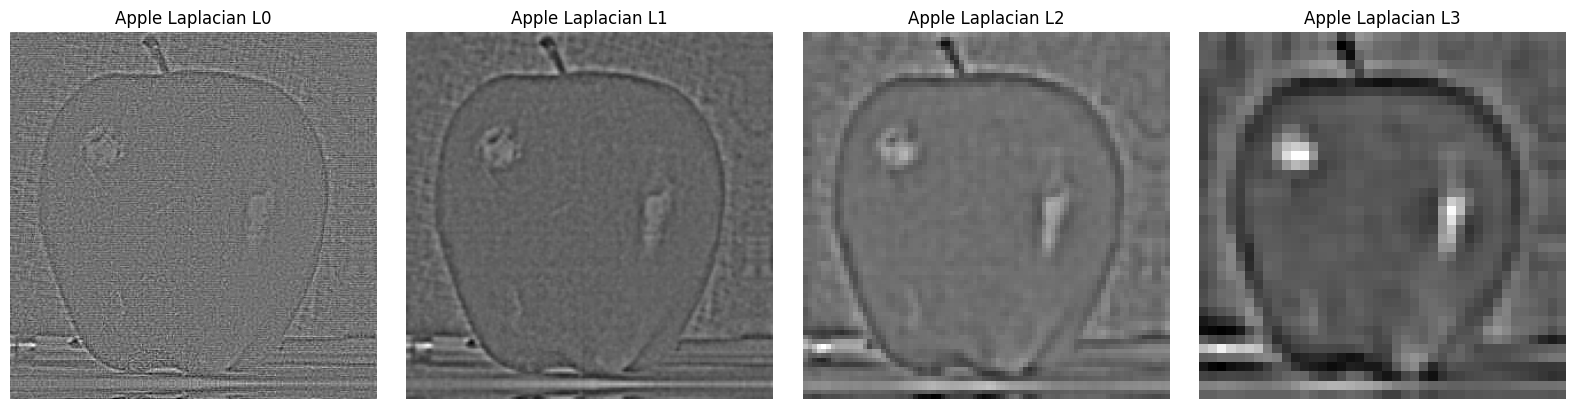

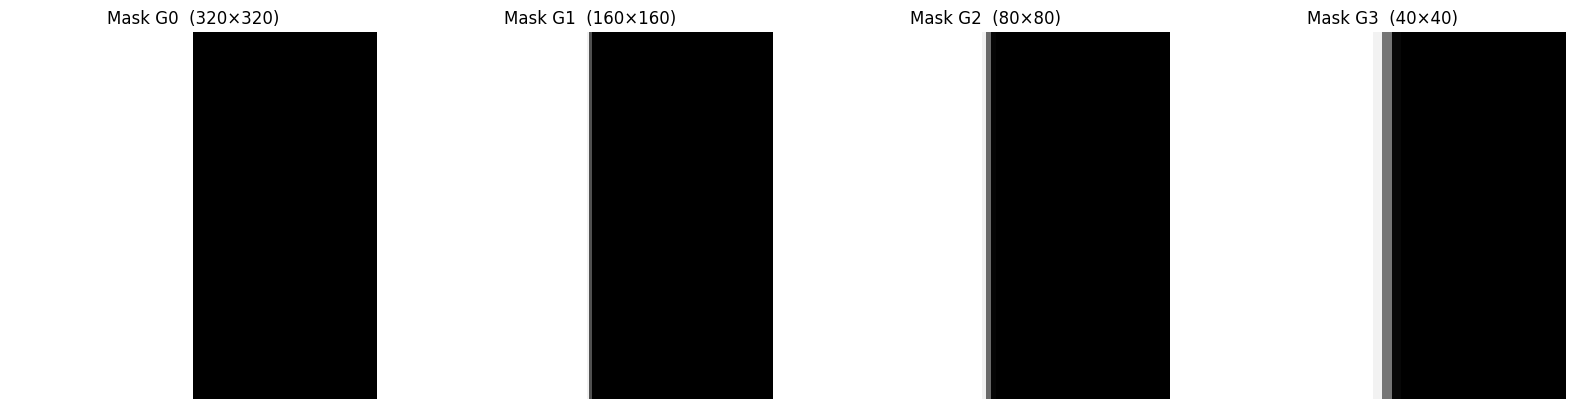

In [22]:
def to_show_float(img):
    """Laplacian levels can be negative; shift for display only."""
    vis = img.copy()
    if vis.ndim == 3:
        vis = cv2.cvtColor(np.clip(vis, -255, 255).astype(np.float32), cv2.COLOR_BGR2GRAY)
    vis = vis - vis.min()
    if vis.max() > 0:
        vis = vis / vis.max()
    return vis


n_show = min(4, LEVELS)

plt.figure(figsize=(16, 4))
for i in range(n_show):
    plt.subplot(1, n_show, i + 1)
    plt.imshow(to_show_float(lp_a[i]), cmap="gray")
    plt.title(f"Apple Laplacian L{i}")
    plt.axis("off")
plt.tight_layout()
plt.show()

plt.figure(figsize=(16, 4))
for i in range(n_show):
    plt.subplot(1, n_show, i + 1)
    m = gp_m[i][:, :, 0]
    plt.imshow(m, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    plt.title(f"Mask G{i}  ({m.shape[1]}×{m.shape[0]})")
    plt.axis("off")
plt.tight_layout()
plt.show()

### Task 5 method and observations

**Pipeline**
1. Load both images; resize to a shared `(H, W)` so they overlay.
2. Pad so `H` and `W` are divisible by $2^{L-1}$ (here $L=6$). `pyrDown` then `pyrUp` must hit the exact previous size (`dstsize`).
3. **Gaussian pyramid:** `G_0 =` image, `G_{k+1} = pyrDown(G_k)` (blur + subsample).
4. **Laplacian pyramid:** `L_k = G_k − pyrUp(G_{k+1})` for $k=0..L-2$, and `L_{L-1} = G_{L-1}`. Each `L_k` holds band-pass detail.
5. **Mask:** 1 on the left half (apple), 0 on the right (orange). Its Gaussian pyramid creates a **wider transition at coarser levels**.
6. **Blend:** $L_k^{\text{out}} = G_k^{\text{mask}} L_k^{A} + (1-G_k^{\text{mask}}) L_k^{B}$.
7. **Reconstruct:** start from the coarsest level, `pyrUp` and add the next Laplacian, up to full resolution.

**Result:** the fruit looks like a single object: apple skin on the left, orange texture on the right, with no vertical cut. Lighting and background green mix smoothly across the center. The hard-split figure still shows a crack down the middle — that is what a single-scale copy-paste does, and why the assignment asks for pyramids.

Levels: too few ($L=2$) → residual seam; too many on a small image → the coarsest level is tiny and can look blocky. Six levels is appropriate for these $300\times300$-class photos.

Reference: P. Burt and E. Adelson, “A Multiresolution Spline With Application to Image Mosaics,” *ACM Transactions on Graphics*, 1983.

## Conclusion

This assignment compared four classical low-level operations on real images.

**Edges (Canny).** Hysteresis controls how much weak structure is kept. For `uni.jpeg`, **(80, 160)** outlined buildings and paths but still included vegetation and pavement texture. **(30, 90)** added even more weak edges; **(150, 300)** dropped faint contours and left stronger building and shadow lines.

**Smoothing (Gaussian composition).** One blur with $\sigma = 2\sqrt{2}$ matched two blurs with $\sigma = 2$. The pixel-wise difference had **max = 1** and **mean ≈ 0.077**, as expected from adding Gaussian variances. Residual error is discrete kernels and `uint8` rounding, not a different blur.

**Impulse denoising.** After replacing **30%** of pixels with salt-and-pepper noise, **median 7×7** recovered a usable campus image. Gaussian turned impulses into haze. Bilateral kept many black and white dots because they look like edges in range space. The right filter follows the noise model: median for outliers, not a linear or edge-preserving average.

**Multiresolution blending.** Laplacian pyramids plus a Gaussian-smoothed left/right mask produced a seamless apple–orange composite. Low-frequency color mixes over a wide region; high-frequency peel texture mixes only near the seam. A hard split still shows a vertical crack. That is the point of Burt and Adelson (1983) versus copy-paste at a single scale.

Classical OpenCV operators are simple to call; **parameters and the operator that matches the degradation** decide whether the result is useful.